# Steam game Recommender System - Content-Based

## Machine Learning Steps:

1. Data Collection and Preprocessing:

- 1.1 Import dataset
- 1.2 Merge dataframes based on 'steam_appid'
- 1.3 Normalize text data

2. Feature Extraction:

- 2.1 TF-IDF Vectorization
- 2.2 Count Vectorization

3. Exploratory Data Analysis (EDA):
- 3.1 Conduct descriptive analysis
- 3.2 Identify data patterns and trends

4. Modeling:
- 4.1 Similarity Calculation:
    - 4.1.1 Linear Kernel for similarity measurement
    - 4.1.2 Cosine Similarity for similarity measurement
- 4.2 Benchmark
- 4.3 Pipeline

5. Recommendation Algorithm:
- Develop a content-based recommendation system based on analyzed data

6. Deployment (Gradio)

## Dataset (Kaggle)
- Combined data of 27,000 games scraped from Steam and SteamSpy APIs    
- Source: https://www.kaggle.com/datasets/nikdavis/steam-store-games/data

## Overview & Objective:

**Overview**:
In this project, we will be working with a dataset containing information about different Steam games, including their attributes such as developer, genres, and user ratings. By utilizing natural language processing (NLP) techniques, 

**Objective**:
to suggest games based on their similarities with the user's preferences.

- **Business Type**: Gaming and Entertainment

- **Business Objective**: 
    - Enhance user engagement and satisfaction within the gaming community. By providing personalized game recommendations, 
    - Aim is to increase user retention, drive game exploration, and ultimately contribute to increased game sales and customer loyalty.

- **Learning Problems**: Item similarity

- **Reason for Choosing this Project**: Recommendation systems that can help users navigate through the extensive game options. 

- **Expected Result**: similarity(game attributes, users' interests/user's preferences) = match score

- **Utilization of Results**: recommendation system will be integrated into the Steam platform to provide users with personalized game suggestions directly on their dashboard.

- **Benefits of this Project**:
    - Improved user experience through personalized game recommendations
    - Increased user engagement and retention within the Steam platform
    - Enhanced game exploration, leading to increased game sales and user satisfaction
    - Efficient utilization of the vast library of Steam games, ensuring that users find relevant and enjoyable content tailored to their preferences
    - Insights into user preferences and trends that can inform future game development and marketing strategies within the gaming industry.

# Let's dive in

# **1. Data Collection and Preprocessing:**
- Preprocess the data by handling missing values, converting categorical features into numerical representations, and normalizing numerical features.

- Perform data cleaning and preprocessing on the collected data. This may involve tasks such as text normalization, tokenization, and removing stopwords.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

In [ ]:
cmap = sns.color_palette("ch:start=.2,rot=-.3", as_cmap=True)

## 1.1 Import dataset

In [ ]:
steam = pd.read_csv(
    r"D:\Repo\DS\RecommenderSystem\Content-Based-SteamGame\repository\steam.csv")
steam_description = pd.read_csv(
    r"D:\Repo\DS\RecommenderSystem\Content-Based-SteamGame\repository\steam_description_data.csv")
steam_media_data = pd.read_csv(
    r"D:\Repo\DS\RecommenderSystem\Content-Based-SteamGame\repository\steam_media_data.csv")

In [ ]:
steam.head()

In [ ]:
steam_description.head()


In [ ]:
steam_media_data.head()


In [ ]:
steam.isna().sum()


## 1.2 Data Merging
merge 3 dataframe by 'steam_appid'

In [ ]:
steam = steam.rename(columns={'appid': 'steam_appid'})

In [ ]:
merged_df = steam.merge(steam_description, on='steam_appid', how='left').merge(
    steam_media_data, on='steam_appid', how='left')

In [ ]:
merged_df

In [ ]:
merged_df.isna().sum()

In [ ]:
merged_df.loc[merged_df['developer'].isna()]


In [ ]:
merged_df.loc[merged_df['publisher'].isna()]


In [ ]:
merged_df.shape

In [ ]:
merged_df.drop_duplicates(subset='steam_appid', inplace=True)
merged_df.shape


In [ ]:
merged_df.isna().sum()

In [ ]:
merged_df.dropna(subset=['developer', 'publisher'], inplace=True)
merged_df.isna().sum()

In [ ]:
merged_df.shape

In [ ]:
merged_df["name"].value_counts()

In [ ]:
merged_df.nunique()


In [ ]:
merged_df['english'].value_counts()


In [ ]:
merged_df['platforms'].value_counts()


In [ ]:
merged_df['required_age'].value_counts()

In [ ]:
numeric_cols = merged_df.select_dtypes(
    include=['int64', 'float64']).columns.to_list()
numeric_cols

In [ ]:
merged_df[numeric_cols].describe().T

In [ ]:
merged_df['total_ratings'] = merged_df['positive_ratings'] - merged_df['negative_ratings']

In [ ]:
merged_df['total_ratings']


In [ ]:
merged_df.describe().T

In [ ]:
merged_df = merged_df.drop(
    merged_df[merged_df['total_ratings'] <= 10].index).reset_index(drop=True)

In [ ]:
merged_df.shape

In [ ]:
merged_df = merged_df.drop(
    merged_df[merged_df['english'] == 0].index).reset_index(drop=True)

In [ ]:
merged_df.shape


In [ ]:
merged_df.to_csv('metadata.csv', index=False)

## 1.3 Text Normalization
converting text data into a standardized or normalized form and to clean and make the text consistent.

- **1. Lowercasing**: Converting all text to lowercase to ensure uniformity. For example, "Hello" and "hello" become "hello."
- **2. Removing Punctuation**: Removing punctuation marks such as periods, commas, and quotation marks to focus on the text content.
- **3. Removing Stopwords**: Stopwords are common words (e.g., "the," "and," "in") that are often removed from text because they don't carry significant meaning for many NLP tasks.
- **4. Stemming and Lemmatization**: Reducing words to their root or base form. For example, "running" becomes "run." Stemming is more aggressive and might produce non-real words, while lemmatization ensures that the resulting word is a real one.
- **5. Handling Accents and Diacritics**: Replacing accented characters with their unaccented equivalents. For example, "café" becomes "cafe."
- **6. Handling Contractions**: Expanding contractions, such as changing "I've" to "I have." | "She'd" to She would" | "I'll" to "I will"
- **7. Handling Special Characters**: Replacing or removing special characters or symbols that are not relevant to the analysis.

Text normalization helps in reducing the dimensionality of the text data, making it more consistent, and ensuring that the text is prepared for further processing.

In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import RegexpTokenizer
from nltk.stem import WordNetLemmatizer
from nltk.stem import PorterStemmer
import contractions

from unidecode import unidecode

nltk.download('wordnet')
nltk.download('stopwords')

In [ ]:
# 1. Lowercasing:
def lowercase(string):
    return str(string).lower()

# 2. Removing Punctuation:
def remove_punctuation(string):
    tokenizer = RegexpTokenizer(r'\w+')
    string = tokenizer.tokenize(string)
    string = " ".join(string)
    return string 
# 3. Removing Stopwords:
def remove_stop_words(string):
    string = string.split()
    stops = set(stopwords.words("english"))
    string = [w for w in string if not w in stops]
    string = " ".join(string)
    return string

# 4. Stemming:
def stemming(string):
    stemmer = PorterStemmer()
    words = string.split()
    stemmed_words = [stemmer.stem(word) for word in words]
    return ' '.join(stemmed_words)


# 5. Lemmatization :
def lemmatization(string):
    lemmatizer = WordNetLemmatizer()

    words = string.split(' ')
    lemmatized_words = [lemmatizer.lemmatize(word) for word in words]
    return ' '.join(lemmatized_words)

# 6. Handling Accents and Diacritics Function:
def handle_accents_and_diacritics(string):
    return unidecode(string)

# 7. Handling Contractions Function:
def handle_contractions(string):
    # creating an empty list
    expanded_words = []
    for word in string.split():
        # using contractions.fix to expand the shortened words
        expanded_words.append(contractions.fix(word))

    expanded_text = ' '.join(expanded_words)
    return expanded_text
# 8. Handling Special Characters Function:

def handle_special_characters(string):
    return re.sub(r'[^a-zA-Z0-9\s]', ' ', string)


In [ ]:
# Others
def globalization(string: str):
    return str(string).replace(';', ' ')


def remove_html(string):
    html_pattern = re.compile('<.*?>')
    return html_pattern.sub(r'', string)


### Example 1: After apply each **function**

In [ ]:
sample_text = "I've a cat and café, I do like petting cats in daily"

In [ ]:
# Lower case
lowercase(sample_text)

In [ ]:
# remove ' and ,
remove_punctuation(sample_text)

In [ ]:
# remove a,do,not, to, in
remove_stop_words(sample_text)

In [ ]:
# Change daily  to daili
stemming(sample_text)

In [ ]:
# Change cats to cat
lemmatization(sample_text)


In [ ]:
# Change café to cafe
handle_accents_and_diacritics(sample_text)

In [ ]:
# Change I've to I have
handle_contractions(sample_text)

In [ ]:
# remove non-acii
handle_special_characters(sample_text)

In [ ]:
def text_normalization(string):
    string = handle_contractions(string)
    string = handle_accents_and_diacritics(string)
    string = remove_punctuation(string)
    string = remove_stop_words(string)
    # string = stemming(string)
    string = lemmatization(string)
    string = handle_special_characters(string)
    string = lowercase(string)
    return string

### Example 2: sort **function** and oberve before/after

In [ ]:
sampled_indexes = merged_df.sample(10).index

# Process text_normalization function on the sampled text
for index in sampled_indexes:
    print(f"Index: {index}")
    sample_text = merged_df.loc[index, 'short_description']
    print(f"Length of Text: {len(sample_text)} characters")
    print(f"Original Text: {sample_text}")
    print('-'*10)
    normalized_text = text_normalization(sample_text)
    print(f"Length of Text: {len(normalized_text)} characters")
    print(f"Normalized Text: {normalized_text}")
    print('-'*100)

    print("\n")


### Apply

select game contents:
- name
- developer
- genres
- steamspy_tags 
- short_description (computation & memory constraints)
- header_image (optional, for display image)

for put in model and make model do item similarity job

In [ ]:
df_rec = merged_df[['steam_appid', 
                    'name',
                    'developer', 
                    'genres',
                    'steamspy_tags', 
                    # this is informative content, But my local PC can't take this high computation ;_;, So I decided not to put in cosine similarity
                    'short_description', 
                    # For display image of game
                    'header_image']]
df_rec

In [ ]:
steam_content_cols = ['name', 'developer', 'genres', 'steamspy_tags']

In [ ]:
for col in steam_content_cols:
    df_rec[col] = df_rec[col].apply(text_normalization)

In [ ]:
df_rec[steam_content_cols]

In [ ]:
steam_descrip_cols = ['short_description']

In [ ]:
for col in steam_descrip_cols:
    df_rec[col] = df_rec[col].apply(text_normalization)

In [ ]:
df_rec[steam_descrip_cols]

# 2. **Feature Extraction**

- 2.1 TF-IDF Vectorization
- 2.2 Count Vectorization

Objective: 
- Transform categorical features like 
    - 'genres'
    - 'categories' 
    -  'steamspy_tags' 
    
into binary vectors using techniques like one-hot encoding or TF-IDF (Term Frequency-Inverse Document Frequency).

## Combine **Genre** & **Steam_tags**
**Reason**: These 2 features are a little bit duplicated, So combine it and remove the duplicated

In [ ]:
df_rec['genres&tags'] = df_rec['genres'] + ' ' + df_rec['steamspy_tags']

In [ ]:
df_rec['genres&tags']


In [ ]:
def del_duplicate_tag(string: str):
    spl_string = string.split()
    return ' '.join(sorted(set(spl_string), key=spl_string.index))

In [ ]:
df_rec['genres&tags'] = df_rec['genres&tags'].apply(del_duplicate_tag)

## Combine all content
combine related content
- name
- developer
- geres&tag

to put in Vectorizer

In [ ]:
df_rec['all'] = df_rec['name'] + ' ' + \
    df_rec['developer'] + ' ' + df_rec['genres&tags']

In [ ]:
df_rec['all']

In [ ]:
list(df_rec['all'])

## **2.1 TF-IDF Vectorizer**

### **TF-IDF (Term Frequency-Inverse Document Frequency) Vectorizer**

TF-IDF is a widely used technique for converting text data into numerical feature vectors. It measures the importance of words in a document relative to their frequency in a corpus of documents. We'll dive into the concepts of TF (Term Frequency) and IDF (Inverse Document Frequency) and see how TF-IDF can be used to represent textual data.

- TF(t , d) is the number of occurrences of  “t” in document “d”
- t is term or text
- d is document or corpus

$$TF(t,d) = \frac{\text{Number of words appearing in the document}}{\text{Total number of words in the document}}$$



### **Inverse Document Frequency (IDF)**

IDF reflects the proportion of documents in the corpus that contain a specific term. Unique terms receive higher importance scores than common ones.

- IDF(t) = log [ (1 + n) / (1 + DF(t)) ] + 1
- t is term or 1 word
- n is the total number of documents present.
- DF(t) is the number of documents found for word t.

$$IDF(t, D) = \log_e\left(\frac{\text{Total number of documents in D}}{\text{Number of documents containing term t}}\right)$$


### **TF-IDF**

TF-IDF is calculated by multiplying TF and IDF scores.

$$\text{TF-IDF}=TF×IDF$$

The results can be used to find similarity values.

Source: 
- [LearnDataSci](https://www.learndatasci.com/glossary/tf-idf-term-frequency-inverse-document-frequency/)
- [TF-IDF ทำงานยังไง](https://www.softnix.co.th/2019/05/28/tf-idf-%E0%B8%97%E0%B8%B3%E0%B8%87%E0%B8%B2%E0%B8%99%E0%B8%A2%E0%B8%B1%E0%B8%87%E0%B9%84%E0%B8%87/)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
import time

In [ ]:
time_start = time.time()

tfidf_vectorizer = TfidfVectorizer(lowercase=True, stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(df_rec['all'])

time_end = time.time()
print(
    f"TF-IDF Vectorizer: {round(time_end - time_start, 2)} second")
print(f'TF-IDF  shape: {tfidf_matrix.shape}')
feature_names = tfidf_vectorizer.get_feature_names_out()
print("Feature Names (Terms):", feature_names)
stop_words = tfidf_vectorizer.get_stop_words()
print("Stop Words:", stop_words)
vocabulary = tfidf_vectorizer.vocabulary_
print("Vocabulary:", vocabulary)

### What is Vectorizer done looks like?

In [ ]:
pd.DataFrame(tfidf_matrix.toarray(),columns=tfidf_vectorizer.get_feature_names_out())

In [ ]:
tfidf_df = pd.DataFrame([vocabulary])
tfidf_df = pd.DataFrame(
    list(vocabulary.items()), columns=['Vocabulary', 'Count'])
tfidf_df.sort_values(by='Count', ascending=False)

In [ ]:
from wordcloud import WordCloud, STOPWORDS

In [ ]:
text = ' '.join(tfidf_df['Vocabulary'])

plt.rcParams['figure.figsize'] = (15, 15)
wordcloud = WordCloud(background_color='black', colormap='vlag',
                      width=1200, height=1200, max_words=121).generate(text)
plt.imshow(wordcloud)
plt.axis("off")
plt.show()


## **2.2 Count Vectorizer**

### **Count Vectorizer for Text Data**

The Count Vectorizer is a simple method used to convert text data into numerical feature vectors. It essentially counts the frequency of words in a document or corpus and transforms them into a matrix format.

- The Count Vectorizer simply counts the number of occurrences of each word in a document.
- It is a straightforward way to represent textual data in a format that can be fed into various algorithms.
- It creates a sparse matrix that represents the count of each term in the document.

### **Process of Count Vectorization**

1. **Tokenization:** The text is split into words, phrases, or sentences.
2. **Counting:** The count of each term is recorded.
3. **Matrix Formation:** The count of each term is used to create a matrix.

### **Example of Count Vectorizer**

Suppose we have the following documents:

```css
cssCopy code
["I love to learn", "Natural language processing is interesting", "Machine learning is fun"]

```

Using the Count Vectorizer, the words will be represented in the following matrix format:

```lua
luaCopy code
| "I" | "love" | "to" | "learn" | "natural" | "language" | "processing" | "is" | "interesting" | "machine" | "learning" | "fun" |
|-----|-------|-----|--------|----------|------------|--------------|-----|--------------|---------|-----------|------|
| 1   | 1     | 1   | 1      | 0        | 0          | 0            | 0   | 0            | 0       | 0         | 0    |
| 0   | 0     | 0   | 0      | 1        | 1          | 1            | 1   | 1            | 0       | 0         | 0    |
| 0   | 0     | 0   | 0      | 0        | 0          | 0            | 1   | 0            | 1       | 1         | 1    |

```

This count matrix can be used as input data for various machine learning algorithms.

Sources:

- [Scikit-learn Count Vectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html)

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

In [ ]:
time_start = time.time()

count_vectorizer = CountVectorizer(lowercase=True, stop_words='english')
count_vectorizer_matrix = count_vectorizer.fit_transform(df_rec['all'])

time_end = time.time()
print(
    f"CountVectorizer Vectorizer: {round(time_end - time_start, 2)} second")
print(f'CountVectorizer shape: {count_vectorizer_matrix.shape}')
feature_names = count_vectorizer.get_feature_names_out()
print("Feature Names (Terms):", feature_names)

stop_words = count_vectorizer.get_stop_words()
print("Stop Words:", stop_words)

vocabulary = count_vectorizer.vocabulary_
print("Vocabulary:", vocabulary)


In [ ]:
count_df = pd.DataFrame([vocabulary])
count_df = pd.DataFrame(
    list(vocabulary.items()), columns=['Vocabulary', 'Count'])
count_df.sort_values(by='Count', ascending=False)


### What is Vectorizer done looks like?

In [ ]:
pd.DataFrame(count_vectorizer_matrix.toarray(),columns=count_vectorizer.get_feature_names_out())

In [ ]:
text = ' '.join(count_df['Vocabulary'])

plt.rcParams['figure.figsize'] = (15, 15)
wordcloud = WordCloud(background_color='black', colormap='vlag',
                      width=1200, height=1200, max_words=121).generate(text)
plt.imshow(wordcloud)
plt.axis("off")
plt.show()


# 3. **Exploratory Data Analysis (EDA)**:
- Conduct EDA to gain insights into the dataset, such as game popularity, distribution of genres, categories, tags, and player reviews.
- Visualize key statistics and distributions using plots and graphs.
- Identify correlations and patterns in the data.

In [ ]:
steam.select_dtypes(include=['int64', 'float64']).describe().T

In [ ]:
from scipy.stats import pearsonr


def reg_coef(x, y, label=None, color=None, **kwargs):
    ax = plt.gca()
    r, p = pearsonr(x, y)
    ax.annotate('r = {:.2f}'.format(r), xy=(0.5, 0.5),
                xycoords='axes fraction', ha='center')
    ax.set_axis_off()


g = sns.PairGrid(steam[numeric_cols])
g.map_diag(sns.distplot)
g.map_lower(sns.regplot)
g.map_upper(reg_coef)


In [ ]:
def count_category(data):
  dicts = {}
  for x in data:
    for y in x:
      if y not in dicts.keys():
        dicts[y] = 0
      dicts[y] = int(dicts[y])+1
  return dicts

In [ ]:
categories = steam['categories'].str.split(";")
categories = count_category(categories)
categories

In [ ]:
genres = steam['genres'].str.split(";")
genres = count_category(genres)
genres


In [ ]:
steamspy_tags = steam['steamspy_tags'].str.split(";")
steamspy_tags = count_category(steamspy_tags)
steamspy_tags


In [ ]:
categories_df = pd.DataFrame([categories])
categories_df = pd.DataFrame(list(categories.items()), columns=['Category', 'Count'])
categories_df


In [ ]:
genre_df = pd.DataFrame([genres])
genre_df = pd.DataFrame(
    list(genres.items()), columns=['Genres', 'Count'])
genre_df


In [ ]:
steamspy_tags_df = pd.DataFrame([steamspy_tags])
steamspy_tags_df = pd.DataFrame(
    list(steamspy_tags.items()), columns=['Steamspy_tags', 'Count'])
steamspy_tags_df

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
def plot_bar_chart(dataframe, x_col, y_col, title, x_label, y_label, rotation=0, top=10):
    df_sorted = dataframe.sort_values(by=y_col, ascending=False).head(top)

    plt.figure(figsize=(12, 6))
    bars = plt.bar(df_sorted[x_col], df_sorted[y_col])
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title+ f' (Dispaly Top {top})')
    # Rotate x-axis labels for better readability
    plt.xticks(rotation=rotation)

    for bar in bars:
        height = bar.get_height()
        plt.annotate('{}'.format(height),
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 3),  # 3 points vertical offset
                     textcoords="offset points",
                     ha='center', va='bottom')

    plt.show()


In [ ]:
plot_bar_chart(dataframe=categories_df,
               x_col='Category',
               y_col='Count',
               title='Count of Category Tags',
               x_label='Steamspy Tags',
               y_label='Count',
               rotation=90, 
               top=20)


In [ ]:
plot_bar_chart(dataframe=genre_df,
               x_col='Genres',
               y_col='Count',
               title='Count of Category Genres',
               x_label='Genres',
               y_label='Count',
               rotation=90,
               top=20)


In [ ]:
plot_bar_chart(dataframe=steamspy_tags_df,
               x_col='Steamspy_tags',
               y_col='Count',
               title='Count of Steamspy Tags',
               x_label='Steamspy Tags',
               y_label='Count',
               rotation=90,
               top=20)


# 4. **Modeling**:
We use two methods for similarity calculation: **Linear Kernel** and **Cosine Similarity**.

## Content-Based Similarity
In the context of a content-based recommendation system, we utilize two primary methods for measuring similarity between different items:

- **Linear Kernel** measures the linear relationship between different data points. In the context of our content-based recommendation system, the linear kernel helps assess the relationship between different game attributes and features, enabling the identification of games with similar characteristics.


- **Cosine Similarity** is the measure of similarity between two vectors, Similarity between two vectors (A and B) is calculated by taking the dot product of the two vectors and dividing it by the magnitude value. 

In [ ]:
from sklearn.metrics.pairwise import linear_kernel
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
# Optional
from IPython.display import display, HTML
import time


## Benchmarking

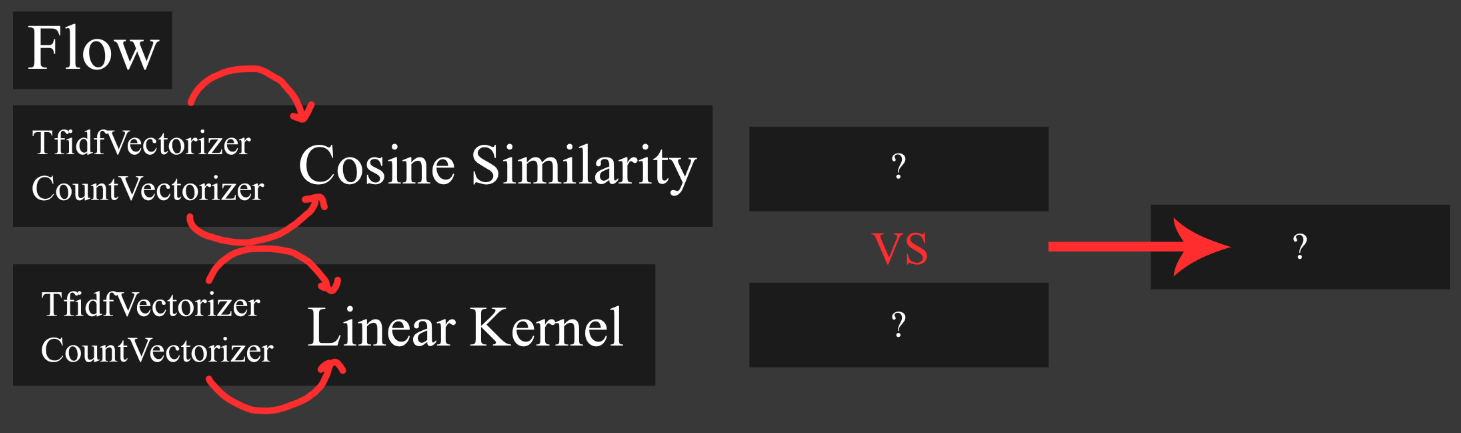

Consine Similarity
- TF-IDF Vectorizer 
- Count Vectorizer

In [ ]:
tfidf_matrix.shape

In [ ]:
count_vectorizer_matrix.shape

In [ ]:
time_start = time.time()

cosine_TfidV = cosine_similarity(tfidf_matrix, tfidf_matrix)
time_end = time.time()
print(f"Cosine Similarity + TF-IDF Vectorizer: {round(time_end - time_start, 2)} second")
cosine_TfidV.shape

In [ ]:
time_start = time.time()

cosine_countV = cosine_similarity(
    count_vectorizer_matrix, count_vectorizer_matrix)

time_end = time.time()
print(f"Cosine Similarity + Count Vectorizer: {round(time_end - time_start, 2)} second")
cosine_countV.shape


Linear Kernel
- TF-IDF Vectorizer 
- Count Vectorizer

In [ ]:
time_start = time.time()

linear_kernel_TfidV = linear_kernel(tfidf_matrix, tfidf_matrix)
time_end = time.time()
print(
    f"Linear kernel + TF-IDF Vectorizer: {round(time_end - time_start, 2)} second")
linear_kernel_TfidV.shape


In [ ]:
time_start = time.time()

linear_kernel_countV = linear_kernel(
    count_vectorizer_matrix, count_vectorizer_matrix)
time_end = time.time()
print(
    f"Linear kernel + Count Vectorizer: {round(time_end - time_start, 2)} second")
linear_kernel_countV.shape


In [ ]:
def nearest_name(name: str, verbose=1):
    result = merged_df[merged_df['name'].str.startswith(name[:-1])]
    close = get_close_matches(name)
    if verbose==1:
        display(HTML(result[['name', 'developer', 'genres','steamspy_tags']].to_html()))
    if len(result) != 0:
        return result.index[0]
    elif close:
        return close[0]
    else:
        return None
    

def get_close_matches(name: str):
    result = merged_df.loc[merged_df['name'].apply(
        lambda x: x.lower()).str.contains(name.lower())]
        
    if len(result) != 0:
        return result
    return []


Criterion of benchmarking:
- Name correction
- Time Performance

In [ ]:
a_game = "Counter-Strike"
b_game = "Half-Life"
c_game = "Tom Clancy's Rainbow Six"

In [ ]:
nearest_name(name=a_game)

In [ ]:
nearest_name(name=b_game)


In [ ]:
nearest_name(name=c_game)


## Similarity function
have 2 functions consist: 
- similarity with nearest name = figure out itself and find the closest name
- similarity with indice = required the exact name in DataFrame

In [ ]:
# similarity_nearest_name is figure out itself and find the closest name
def similarity_nearest_name(name: str, similarity_vectorizer):

    ind = nearest_name(name=name,verbose=0)
    cos_score = list(enumerate(similarity_vectorizer[ind]))

    cos_score = sorted(cos_score, key=lambda x: x[1], reverse=True)
    cos_score = cos_score[0:10]
    ten_ind = [i[0] for i in cos_score]
    df = df_rec[['name', 'developer', 'genres&tags']].iloc[ten_ind]

    score = [i[1] for i in cos_score]
    score = [round(num, 4) for num in score]

    df = pd.DataFrame({'name': df['name'],
                       'developer': df['developer'],
                       'genres&tags': df['genres&tags'],
                       'match_score': score
                       })
    average_match_score = df['match_score'].mean()
    print(f'Average Match Score: {average_match_score:.4f}')
    return df

In [ ]:
# similarity_indices is required the exact name in DataFrame
def similarity_indices(name: str, similarity_vectorizer):
    indices = pd.Series(df_rec.index, index=df_rec['name'])

    ind = indices[name]
    cos_score = list(enumerate(similarity_vectorizer[ind]))

    cos_score = sorted(cos_score, key=lambda x: x[1], reverse=True)
    cos_score = cos_score[0:10]
    ten_ind = [i[0] for i in cos_score]
    df = df_rec[['name', 'developer', 'genres&tags']].iloc[ten_ind]

    score = [i[1] for i in cos_score]
    score = [round(num, 4) for num in score]

    df = pd.DataFrame({'name': df['name'],
                       'developer': df['developer'],
                       'genres&tags': df['genres&tags'],
                       'match_score': score
                       })
    average_match_score = df['match_score'].mean()
    print(f'Average Match Score: {average_match_score:.4f}')
    return df

# Cosine Similarity + TF-IDF Vectorizer

In [ ]:
similarity_nearest_name(name=a_game, similarity_vectorizer=cosine_TfidV)

# Cosine Similarity + Count Vectorizer

In [ ]:
similarity_nearest_name(name=a_game, similarity_vectorizer=cosine_countV)


# Linear  Similarity + TF-IDF Vectorizer

In [ ]:
similarity_nearest_name(name=a_game, similarity_vectorizer=linear_kernel_TfidV)


# Linear Similarity + Count Vectorizer

In [ ]:
similarity_nearest_name(name=a_game, similarity_vectorizer=linear_kernel_countV)

# 5. **Recommendation Algorithm**:
- Use the similarity matrix to implement a content-based recommendation algorithm. The algorithm can follow these steps:
    - For a given game, calculate its similarity scores with all other games in the dataset.
    - Select the top N games with the highest similarity scores as recommendations.
    - Filter out games the user has already interacted with or owns.
    - Present the recommended games to the user.

In [ ]:
import requests
from PIL import Image
from io import BytesIO

In [ ]:
def recommendations(name: str, similarity_vectorizer):

    ind = nearest_name(name=name, verbose=0)
    cos_score = list(enumerate(similarity_vectorizer[ind]))

    cos_score = sorted(cos_score, key=lambda x: x[1], reverse=True)
    cos_score = cos_score[0:10]
    ten_ind = [i[0] for i in cos_score]
    df = merged_df[['name', 'developer',  'genres',
                    'steamspy_tags',
                 'header_image']].iloc[ten_ind]
    score = [i[1] for i in cos_score]
    score = [round(num, 4) for num in score]

    df = pd.DataFrame({'name': df['name'],
                       'developer': df['developer'],
                       'genres': df['genres'],
                       'steamspy_tags':df['steamspy_tags'],
                       'header_image': df['header_image'],
                       'match_score': score
                       })

    for index, row in df.iterrows():
        plt.figure(figsize=(1, 1))
        response = requests.get(row['header_image'])
        img = Image.open(BytesIO(response.content))
       
        plt.figure()
        plt.imshow(img)
        plt.title(r'$\bf{' +df['name'].loc[index] + '}$' +
                  f"\nMatch score: {df['match_score'].loc[index]}\nDeveloper: {df['developer'].loc[index]}\nGenres: {df['genres'].loc[index]}\nTags: {df['steamspy_tags'].loc[index]}")
        plt.xlabel(df['match_score'].loc[index])

        plt.show()
    average_match_score = df['match_score'].mean()
    print(f'Average Match Score: {average_match_score:.4f}')
    return df[['name', 'developer',  'genres',
               'steamspy_tags','match_score']]


In [ ]:
merged_df.sort_values(by='positive_ratings', ascending=False).head()

In [ ]:
game_name = "Counter-Strike"
recommendations(name=game_name, similarity_vectorizer=cosine_TfidV)

In [ ]:
game_name = "Tom Clancy's Rainbow Six® Siege"
recommendations(name=game_name, similarity_vectorizer=cosine_TfidV)


In [ ]:
game_name = "Dota"
recommendations(name=game_name, similarity_vectorizer=cosine_TfidV)


In [ ]:
game_name = "PLAYERUNKNOWN"
recommendations(name=game_name, similarity_vectorizer=cosine_TfidV)
